# Quem sustenta o código? Dependência de arquivos em relação a desenvolvedores em projetos open source

**Algoritmos e Estrutura de Dados II · Grafos · Unidade 01 · UFRN**

## 1. Problema e pergunta

Em projetos open source, o conhecimento sobre cada arquivo costuma estar concentrado em poucas pessoas. Se essas pessoas deixam o projeto, os arquivos ficam sem quem os conheça (o chamado *bus factor*).

**Pergunta:** *quais arquivos dependem de poucos desenvolvedores, e quanto do projeto fica "órfão" se os desenvolvedores mais conectados saírem, em comparação com uma saída aleatória?*

**Quem se beneficia:** mantenedores e organizações que usam o projeto e precisam priorizar revisão de código, documentação e mentoria.

**Por que é uma pergunta de rede:** a resposta depende de como autores e arquivos estão ligados, e não de contagens isoladas. Um arquivo com 10 autores e um com 1 autor têm o mesmo número de commits e riscos completamente diferentes.

## 2. Modelagem

| elemento | definição |
|---|---|
| **Nó (tipo A)** | autor (pessoa, identificada por e-mail e nome normalizados) |
| **Nó (tipo F)** | arquivo existente no `HEAD` do repositório |
| **Aresta** | o autor alterou o arquivo em pelo menos um commit |
| **Peso** | número de commits do autor naquele arquivo |
| **Direção** | não há. A relação "alterou" é simétrica para a pergunta (quem toca em quê) |
| **Tipo de grafo** | bipartido, simples, ponderado |

**O que ficou de fora:** commits de merge (não representam autoria de conteúdo), contas de bot, arquivos removidos ao longo da história, renomeações (um arquivo renomeado perde o histórico anterior) e arquivos de ruído que todos tocam (changelog e lockfiles). Quantidade de linhas alteradas e qualidade das mudanças também não entram.

## 3. Configuração e coleta dos dados

In [1]:
import subprocess, re, random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import networkx as nx
from networkx.algorithms import bipartite, community
import matplotlib.pyplot as plt
from scipy import sparse

import analise as an   # funções compartilhadas com a aplicação (analise.py)

# ---------- parâmetros (mude aqui para analisar outro projeto) ----------
REPO_URL  = "https://github.com/pallets/flask.git"   # ex.: git/git, torvalds/linux (grande!), django/django
REPO_SHA  = "d086db856be187255b8ec61ef409357393020f32"  # versão analisada (fixa os resultados); None = mais recente
REPO_DIR  = Path("repos") / "flask"
DATA_DIR  = Path("data");    DATA_DIR.mkdir(exist_ok=True)
FIG_DIR   = Path("figuras"); FIG_DIR.mkdir(exist_ok=True)
SEED      = 42
N_TRIALS  = 200          # repetições da remoção aleatória
MIN_COMMITS_CRITICO = 3  # só avalia concentração em arquivos com pelo menos isto de commits
LIMIAR_CRITICO      = 0.80  # fatia de commits do autor dominante para o arquivo ser crítico
LIMIAR_JACCARD      = 0.30  # corte do esqueleto da projeção de arquivos
RUIDO = re.compile(r"(^|/)(CHANGES\.rst|CHANGELOG.*|.*\.lock|requirements/.*\.txt)$")
BOT   = re.compile(r"\[bot\]|dependabot|pre-commit-ci|github-actions|renovate|imgbot|(?:^|[-_ ])bot$", re.I)

random.seed(SEED); np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
VERDE, CINZA, LARANJA = "#2e7d4f", "#8a8f98", "#d9822b"

def git(*args):
    return subprocess.run(["git", "-c", "core.quotepath=false", *args], cwd=REPO_DIR,
                          check=True, capture_output=True, text=True, encoding="utf-8", errors="replace").stdout

if not REPO_DIR.exists():
    REPO_DIR.parent.mkdir(exist_ok=True)
    subprocess.run(["git", "clone", "--quiet", REPO_URL, str(REPO_DIR)], check=True)
if REPO_SHA:
    git("checkout", "--quiet", REPO_SHA)
print("Repositório:", REPO_URL, "| commits (sem merges):", git("rev-list", "--no-merges", "--count", "HEAD").strip())

Repositório: https://github.com/pallets/flask.git | commits (sem merges): 3829


In [2]:
raw = git("log", "--no-merges", "--name-only", "--pretty=format:@@%H%x1f%an%x1f%ae%x1f%at")

rows, cur = [], None
for line in raw.splitlines():
    if line.startswith("@@"):
        h, nome, email, ts = line[2:].split("\x1f")
        cur = (h, nome.strip(), email.strip().lower(), int(ts))
    elif line.strip() and cur:
        rows.append((*cur, line.strip()))

df = pd.DataFrame(rows, columns=["commit", "nome", "email", "ts", "arquivo"])
print(f"{len(df):,} registros commit-arquivo | {df.commit.nunique():,} commits")
df.head()

9,317 registros commit-arquivo | 3,828 commits


,commit,nome,email,ts,arquivo
0,d086db856be187255b8ec61ef409357393020f32,David Lord,davidism@gmail.com,1791381774,src/flask/sansio/app.py
1,329c32b916938d33fec41f40eb7ed854bf0b3e2b,David Lord,davidism@gmail.com,1791381700,src/flask/app.py
2,329c32b916938d33fec41f40eb7ed854bf0b3e2b,David Lord,davidism@gmail.com,1791381700,tests/test_testing.py
3,41cb747cd5a9b43da43bf809ad974722542603db,David Lord,davidism@gmail.com,1791381416,CHANGES.rst
4,7689f98403e2c0b0bc8d1031e60f8cff2620e86a,David Lord,davidism@gmail.com,1791380834,.github/workflows/tests.yaml


### 3.1 Limpeza

Quatro decisões, todas registradas porque mudam a rede:

1. **Bots** removidos (regex em nome e e-mail).
2. **Identidade do autor:** a mesma pessoa aparece com e-mails diferentes. Cada e-mail é mapeado para o nome mais frequente associado a ele, e o autor passa a ser esse nome.
3. **Arquivos** restritos aos que existem no `HEAD` (`git ls-files`).
4. **Ruído:** changelog e lockfiles são tocados por todos e inflariam as ligações sem indicar conhecimento do código.

In [3]:
antes = len(df)
df = df[~(df.nome.str.contains(BOT) | df.email.str.contains(BOT))]
print("registros de bots removidos:", antes - len(df))

# identidade: e-mail -> nome mais frequente
nome_do_email = df.groupby("email").nome.agg(lambda s: s.value_counts().idxmax())
df["autor"] = df.email.map(nome_do_email)
print("nomes distintos:", df.nome.nunique(), "-> autores após unificação:", df.autor.nunique())

# arquivos existentes no HEAD, sem ruído
head = set(git("ls-files").splitlines())
antes = len(df)
df = df[df.arquivo.isin(head) & ~df.arquivo.str.match(RUIDO)]
print("registros removidos (arquivo inexistente no HEAD ou ruído):", antes - len(df))

arestas = (df.groupby(["autor", "arquivo"])
             .agg(commits=("commit", "nunique"), ultimo_ts=("ts", "max")).reset_index())
registros = df[["commit", "ts", "autor", "arquivo"]]   # nível commit–arquivo, usado na seção 7.11
print(f"{arestas.autor.nunique()} autores · {arestas.arquivo.nunique()} arquivos · {len(arestas)} arestas")
arestas.to_csv(DATA_DIR / "arestas_autor_arquivo.csv", index=False)
arestas.sort_values("commits", ascending=False).head()

registros de bots removidos: 230


nomes distintos: 854 -> autores após unificação: 833
registros removidos (arquivo inexistente no HEAD ou ruído): 5018
569 autores · 234 arquivos · 1527 arestas


,autor,arquivo,commits,ultimo_ts
473,David Lord,src/flask/app.py,88,1791381700
92,Armin Ronacher,docs/api.rst,71,1464288737
514,David Lord,tests/test_basic.py,65,1791380834
471,David Lord,src/flask/__init__.py,63,1743287014
340,David Lord,.pre-commit-config.yaml,61,1785432354


## 4. Construção da rede bipartida

In [4]:
B = nx.Graph()
autores  = sorted(arestas.autor.unique())
arquivos = sorted(arestas.arquivo.unique())
B.add_nodes_from([("a:" + a, {"bipartite": 0, "nome": a}) for a in autores])
B.add_nodes_from([("f:" + f, {"bipartite": 1, "nome": f}) for f in arquivos])
B.add_weighted_edges_from(("a:" + r.autor, "f:" + r.arquivo, r.commits) for r in arestas.itertuples())

A_nodes = [n for n, d in B.nodes(data=True) if d["bipartite"] == 0]
F_nodes = [n for n, d in B.nodes(data=True) if d["bipartite"] == 1]
assert bipartite.is_bipartite(B)

n_a, n_f, m = len(A_nodes), len(F_nodes), B.number_of_edges()
print(f"autores: {n_a} | arquivos: {n_f} | arestas: {m}")
print(f"densidade bipartida = m / (|A|·|F|) = {m / (n_a * n_f):.5f}")

autores: 569 | arquivos: 234 | arestas: 1527
densidade bipartida = m / (|A|·|F|) = 0.01147


## 5. Estrutura da rede

### 5.1 Grau e distribuição de grau *(semana 2)*

Em uma rede bipartida há duas distribuições: **arquivos por autor** (quanto cada pessoa abrange) e **autores por arquivo** (quão compartilhado é cada arquivo).

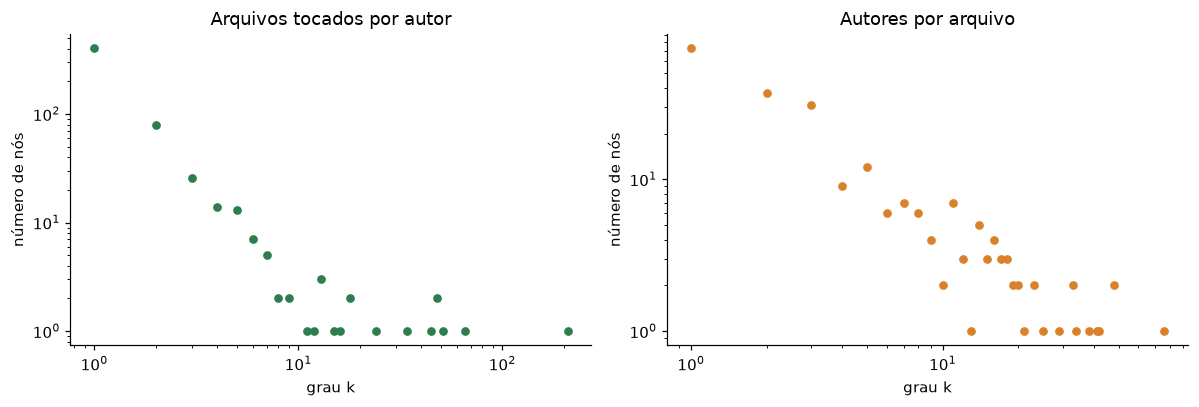

Autores com 1 único arquivo: 70.8%
Arquivos com 1 único autor : 31.2%
mediana de arquivos por autor: 1.0 | mediana de autores por arquivo: 3.0

Top 5 autores por arquivos tocados:
David Lord              209
Armin Ronacher           66
Grey Li                  51
David Baumgold           48
Markus Unterwaditzer     48


In [5]:
deg_autor   = pd.Series({n[2:]: B.degree(n) for n in A_nodes}, name="arquivos_tocados")
deg_arquivo = pd.Series({n[2:]: B.degree(n) for n in F_nodes}, name="n_autores")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, s, titulo, cor in [(ax[0], deg_autor, "Arquivos tocados por autor", VERDE),
                          (ax[1], deg_arquivo, "Autores por arquivo", LARANJA)]:
    cont = s.value_counts().sort_index()
    a.scatter(cont.index, cont.values, color=cor, s=22)
    a.set_xscale("log"); a.set_yscale("log")
    a.set_title(titulo); a.set_xlabel("grau k"); a.set_ylabel("número de nós")
plt.tight_layout(); plt.savefig(FIG_DIR / "distribuicao_grau.png"); plt.show()

print("Autores com 1 único arquivo:", f"{(deg_autor == 1).mean():.1%}")
print("Arquivos com 1 único autor :", f"{(deg_arquivo == 1).mean():.1%}")
print("mediana de arquivos por autor:", deg_autor.median(), "| mediana de autores por arquivo:", deg_arquivo.median())
print("\nTop 5 autores por arquivos tocados:"); print(deg_autor.sort_values(ascending=False).head(5).to_string())

### 5.2 Matriz de adjacência e de incidência *(semanas 2 e 6)*

A matriz de incidência **arquivo × autor** `M` é a representação natural do grafo bipartido. A partir dela saem a projeção dos arquivos (`M·Mᵀ`) e a simulação de remoção.

In [6]:
idx_f = {f: i for i, f in enumerate(arquivos)}
idx_a = {a: j for j, a in enumerate(autores)}
M = sparse.csr_matrix(
    (np.ones(len(arestas)), ([idx_f[f] for f in arestas.arquivo], [idx_a[a] for a in arestas.autor])),
    shape=(len(arquivos), len(autores)))
print("matriz de incidência (arquivos × autores):", M.shape, "| não-zeros:", M.nnz)
assert (np.asarray(M.sum(1)).ravel() == deg_arquivo.reindex(arquivos).values).all()

matriz de incidência (arquivos × autores): (234, 569) | não-zeros: 1527


### 5.3 Componentes conexos *(semana 4)*

Componentes mostram se o projeto é um bloco só ou um conjunto de "ilhas" de conhecimento sem autores em comum.

In [7]:
comps = sorted(nx.connected_components(B), key=len, reverse=True)
gcc = comps[0]
print(f"componentes: {len(comps)}")
print(f"maior componente (GCC): {len(gcc)} nós = {len(gcc)/B.number_of_nodes():.1%} da rede")
print("tamanho dos 5 maiores:", [len(c) for c in comps[:5]])
isolados = [c for c in comps[1:] if len(c) <= 3]
print(f"componentes pequenos (≤3 nós, tipicamente 1 autor + 1-2 arquivos): {len(isolados)}")

componentes: 1
maior componente (GCC): 803 nós = 100.0% da rede
tamanho dos 5 maiores: [803]
componentes pequenos (≤3 nós, tipicamente 1 autor + 1-2 arquivos): 0


### 5.4 Centralidades *(semana 4)*

- **Centralidade de grau:** quanto do outro lado da rede o autor alcança diretamente.
- **Betweenness** (aproximada por amostragem de 300 origens, para caber em redes grandes): autores que **conectam** regiões que sem eles ficariam distantes.

In [8]:
cg = bipartite.degree_centrality(B, A_nodes)
btw = nx.betweenness_centrality(B, k=min(300, B.number_of_nodes()), seed=SEED, normalized=True)

met_autor = pd.DataFrame({
    "autor": autores,
    "arquivos_tocados": [B.degree("a:" + a) for a in autores],
    "commits": [B.degree("a:" + a, weight="weight") for a in autores],
    "centralidade_grau": [cg["a:" + a] for a in autores],
    "betweenness": [btw["a:" + a] for a in autores],
})
met_autor.sort_values("betweenness", ascending=False).head(10)

,autor,arquivos_tocados,commits,centralidade_grau,betweenness
123,David Lord,209,1877,0.893162,0.532888
49,Armin Ronacher,66,467,0.282051,0.112100
180,Grey Li,51,98,0.217949,0.066862
284,Markus Unterwaditzer,48,151,0.205128,0.058627
538,pgjones,45,139,0.192308,0.038949
119,David Baumgold,48,48,0.205128,0.033397
474,defuz,34,83,0.145299,0.027429
378,Ron DuPlain,24,54,0.102564,0.015759
219,Jeff Widman,18,22,0.076923,0.012758
235,Jon S. Stumpf,18,18,0.076923,0.008770


### 5.5 Decomposição em núcleos (k-core) *(semana 5)*

O k-core é o maior subgrafo em que todo nó tem grau ≥ k. Aqui, o núcleo interno agrupa autores e arquivos **densamente entrelaçados**: o coração colaborativo do projeto. A periferia (k = 1) é onde moram as dependências de um único autor.

k máximo (degeneracy): 7
nós por core number: {1: 487, 2: 128, 3: 58, 4: 35, 5: 41, 6: 15} ... {5: 41, 6: 15, 7: 39}

núcleo interno (k=7): 14 autores e 25 arquivos
autores do núcleo: Armin Ronacher, Christian Stade-Schuldt, Daniel Neuhäuser, David Baumgold, David Lord, Grey Li, Jeff Widman, Jon S. Stumpf, Markus Unterwaditzer, Parkayun, Ron DuPlain, ThiefMaster, defuz, pgjones

arquivos na periferia (k=1): 82 (35.0% dos arquivos)


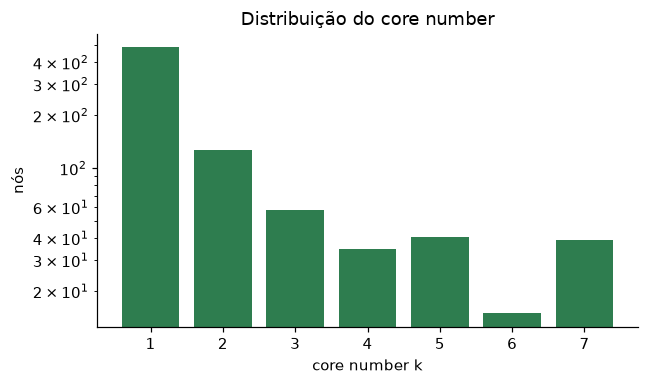

In [9]:
core = nx.core_number(B)
met_autor["core_number"] = [core["a:" + a] for a in autores]
kmax = max(core.values())
print("k máximo (degeneracy):", kmax)

cont = Counter(core.values())
print("nós por core number:", dict(sorted(cont.items())[:6]), "...", dict(sorted(cont.items())[-3:]))

nucleo = [n for n, k in core.items() if k == kmax]
print(f"\nnúcleo interno (k={kmax}): {sum(n.startswith('a:') for n in nucleo)} autores e {sum(n.startswith('f:') for n in nucleo)} arquivos")
print("autores do núcleo:", ", ".join(sorted(n[2:] for n in nucleo if n.startswith('a:')))[:300])

periferia_f = [n for n in F_nodes if core[n] == 1]
print(f"\narquivos na periferia (k=1): {len(periferia_f)} ({len(periferia_f)/n_f:.1%} dos arquivos)")

fig, ax = plt.subplots(figsize=(6, 3.6))
ks = sorted(cont)
ax.bar(ks, [cont[k] for k in ks], color=VERDE)
ax.set_xlabel("core number k"); ax.set_ylabel("nós"); ax.set_yscale("log"); ax.set_title("Distribuição do core number")
plt.tight_layout(); plt.savefig(FIG_DIR / "kcore.png"); plt.show()

## 6. Dependência de arquivos: quais dependem de poucas pessoas?

Um arquivo é marcado como **crítico** quando, tendo pelo menos `MIN_COMMITS_CRITICO` commits, um único autor concentra `LIMIAR_CRITICO` ou mais deles. O filtro de commits evita contar como "crítico" um arquivo tocado uma vez, que é só um arquivo pequeno.

In [10]:
tot  = arestas.groupby("arquivo").commits.sum()
topo = arestas.loc[arestas.groupby("arquivo").commits.idxmax()].set_index("arquivo")

met_arq = pd.DataFrame({
    "n_autores": deg_arquivo,
    "commits": tot,
    "autor_dominante": topo.autor,
    "fatia_dominante": (topo.commits / tot),
    "core_number": pd.Series({n[2:]: core[n] for n in F_nodes}),
}).reindex(arquivos)
met_arq["critico"] = (met_arq.commits >= MIN_COMMITS_CRITICO) & (met_arq.fatia_dominante >= LIMIAR_CRITICO)

n_crit = met_arq.critico.sum()
elegiveis = (met_arq.commits >= MIN_COMMITS_CRITICO).sum()
print(f"arquivos elegíveis (≥{MIN_COMMITS_CRITICO} commits): {elegiveis} de {n_f}")
print(f"arquivos críticos: {n_crit} ({n_crit/elegiveis:.1%} dos elegíveis)")

por_autor = met_arq[met_arq.critico].autor_dominante.value_counts()
met_autor["arquivos_criticos"] = met_autor.autor.map(por_autor).fillna(0).astype(int)
print("\nAutores que sustentam mais arquivos críticos:"); print(por_autor.head(8).to_string())
met_arq[met_arq.critico].sort_values("commits", ascending=False).head(10)[["n_autores", "commits", "autor_dominante", "fatia_dominante"]]

arquivos elegíveis (≥3 commits): 156 de 234
arquivos críticos: 33 (21.2% dos elegíveis)

Autores que sustentam mais arquivos críticos:
autor_dominante
David Lord    33


,n_autores,commits,autor_dominante,fatia_dominante
src/flask/__init__.py,7,70,David Lord,0.900000
.pre-commit-config.yaml,4,64,David Lord,0.953125
.github/workflows/tests.yaml,6,59,David Lord,0.898305
pyproject.toml,5,58,David Lord,0.913793
src/flask/testing.py,6,39,David Lord,0.846154
src/flask/sessions.py,8,36,David Lord,0.805556
.github/workflows/publish.yaml,3,32,David Lord,0.937500
.github/workflows/pre-commit.yaml,1,19,David Lord,1.000000
src/flask/debughelpers.py,3,17,David Lord,0.823529
.github/workflows/lock.yaml,1,16,David Lord,1.000000


### 6.1 Projeção dos arquivos e similaridade de Jaccard *(semana 6)*

Dois arquivos são "irmãos" quando têm as mesmas pessoas por trás. Projetando o grafo bipartido sobre os arquivos, o peso da ligação é a **similaridade de Jaccard** entre os conjuntos de autores: `|A∩B| / |A∪B|`. Um corte por limiar gera o **esqueleto**, e as comunidades dele são **módulos de conhecimento**.

In [11]:
inter = (M @ M.T).tocoo()
tam = np.asarray(M.sum(1)).ravel()
mask = (inter.row < inter.col)
i, j, c = inter.row[mask], inter.col[mask], inter.data[mask]
jac = c / (tam[i] + tam[j] - c)
print(f"pares de arquivos com ao menos 1 autor em comum: {len(jac):,}")

# esqueleto: só arquivos com >=2 autores (arquivos de 1 autor gerariam Jaccard=1 trivial com outros "órfãos" do mesmo autor)
multi = tam >= 2
keep = (jac >= LIMIAR_JACCARD) & multi[i] & multi[j]
S = nx.Graph()
S.add_weighted_edges_from((arquivos[a], arquivos[b], w) for a, b, w in zip(i[keep], j[keep], jac[keep]))
print(f"esqueleto (J ≥ {LIMIAR_JACCARD}, arquivos com ≥2 autores): {S.number_of_nodes()} arquivos · {S.number_of_edges()} ligações")

comun = community.greedy_modularity_communities(S, weight="weight") if S.number_of_edges() else []
comun = sorted(comun, key=len, reverse=True)
print(f"módulos de conhecimento: {len(comun)} | modularidade = {community.modularity(S, comun, weight='weight'):.3f}" if comun else "sem comunidades")
for k, grp in enumerate(comun[:5], 1):
    pasta = Counter(str(Path(f).parent) for f in grp).most_common(1)[0]
    print(f"  módulo {k}: {len(grp)} arquivos | pasta mais comum: {pasta[0]} ({pasta[1]})")

pares de arquivos com ao menos 1 autor em comum: 22,814
esqueleto (J ≥ 0.3, arquivos com ≥2 autores): 116 arquivos · 1057 ligações
módulos de conhecimento: 6 | modularidade = 0.477
  módulo 1: 29 arquivos | pasta mais comum: src\flask (9)
  módulo 2: 28 arquivos | pasta mais comum: docs\patterns (9)
  módulo 3: 26 arquivos | pasta mais comum: examples\tutorial\tests (5)
  módulo 4: 20 arquivos | pasta mais comum: docs\tutorial (7)
  módulo 5: 11 arquivos | pasta mais comum: tests (11)


## 7. Simulação de saída de desenvolvedores

**Hipótese a testar:** a saída das pessoas mais conectadas prejudica o projeto muito mais do que a saída de pessoas ao acaso.

- **Direcionada:** remove os autores em ordem decrescente de arquivos tocados (grau).
- **Aleatória:** remove autores sorteados; média de `N_TRIALS` repetições.
- **Métrica principal, "arquivos órfãos":** fração de arquivos cujos autores foram **todos** removidos. É a perda de cobertura de conhecimento.
- **Métrica secundária:** tamanho do maior componente da rede restante em relação aos nós restantes.

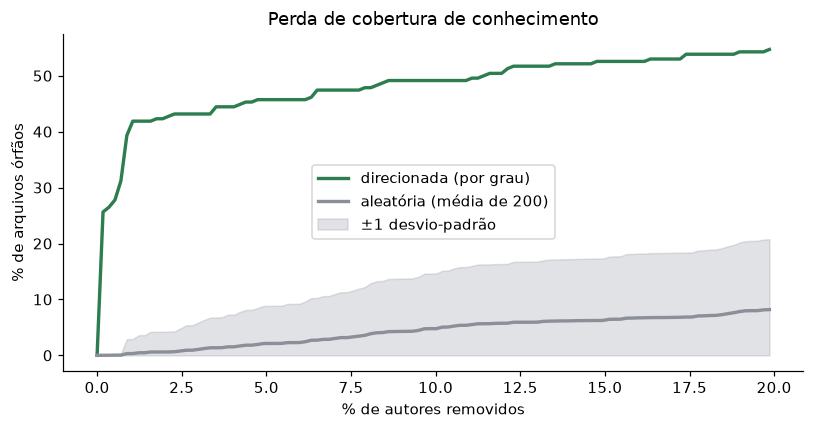

,cenario,autores_removidos_%,k,orfaos_direcionada_%,orfaos_aleatoria_%,razao
0,1 autor (o mais conectado),0.18,1,25.64,0.01,2564.0
1,1% dos autores,1.00,6,41.88,0.32,130.9
2,2% dos autores,2.00,11,42.31,0.60,70.5
3,5% dos autores,5.00,28,45.73,2.11,21.7
4,10% dos autores,10.00,57,49.15,4.78,10.3
5,20% dos autores,20.00,113,54.70,8.18,6.7


In [12]:
Mb = M.tocsc()
grau_ini = np.asarray(M.sum(1)).ravel()

def curva_orfaos(ordem):
    """fração de arquivos órfãos após remover 0,1,2,... autores na ordem dada."""
    rem = grau_ini.copy(); out = [0.0]
    for j in ordem:
        rem = rem - Mb[:, j].toarray().ravel()
        out.append(((rem == 0) & (grau_ini > 0)).mean())
    return np.array(out)

K = int(0.20 * n_a)                                    # até 20% dos autores
ordem_dir = np.argsort(-np.asarray(M.sum(0)).ravel(), kind="stable")  # maior grau primeiro (empate: ordem alfabética)
dir_ = curva_orfaos(ordem_dir[:K])
rng = np.random.default_rng(SEED)
tentativas = np.array([curva_orfaos(rng.permutation(n_a)[:K]) for _ in range(N_TRIALS)])
alea, alea_sd = tentativas.mean(axis=0), tentativas.std(axis=0)

x = np.arange(K + 1) / n_a * 100
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(x, dir_ * 100, color=VERDE, lw=2.2, label="direcionada (por grau)")
ax.plot(x, alea * 100, color=CINZA, lw=2.2, label=f"aleatória (média de {N_TRIALS})")
ax.fill_between(x, np.clip(alea - alea_sd, 0, None) * 100, np.clip(alea + alea_sd, None, 1) * 100, color=CINZA, alpha=.25, label="±1 desvio-padrão")
ax.set_xlabel("% de autores removidos"); ax.set_ylabel("% de arquivos órfãos")
ax.set_title("Perda de cobertura de conhecimento"); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "simulacao_remocao.png"); plt.show()

def na(p): return min(int(round(p * n_a)), K)   # não passa do fim da curva
linhas = [{"cenario": "1 autor (o mais conectado)", "autores_removidos_%": round(100 / n_a, 2), "k": 1,
           "orfaos_direcionada_%": round(dir_[1] * 100, 2), "orfaos_aleatoria_%": round(alea[1] * 100, 2)}]
for p in (0.01, 0.02, 0.05, 0.10, 0.20):
    k = na(p); linhas.append({"cenario": f"{int(p*100)}% dos autores", "autores_removidos_%": int(p * 100), "k": k,
                              "orfaos_direcionada_%": round(dir_[k] * 100, 2),
                              "orfaos_aleatoria_%": round(alea[k] * 100, 2)})
res = pd.DataFrame(linhas); res["razao"] = (res["orfaos_direcionada_%"] / res["orfaos_aleatoria_%"].replace(0, np.nan)).round(1)
res

**Como ler.**
- A primeira saída é a mesma em todas as estratégias e já deixa 25,6% dos arquivos órfãos.
- Para chegar a 50% de órfãos, a ordem por grau precisa de 65 autores, mas a **gulosa precisa de só 19**. O ranking por grau esconde quem é o dono exclusivo dos arquivos periféricos, e o *truck factor* real é bem menor do que o grau sugere.
- Remover pontes (betweenness) é a estratégia **menos** danosa para a cobertura (76 autores para 50%): ponte não é dona. As duas perguntas, circulação e cobertura, pedem medidas diferentes.
- A **definição ponderada** muda a escala: sem uma pessoa, 32% dos arquivos perdem o conhecimento, e com **5 pessoas** metade dos arquivos fica sem quem detenha pelo menos 20% dos commits. A métrica binária de órfão subestima bastante o risco.

In [13]:
def gcc_apos(removidos):
    H = B.copy(); H.remove_nodes_from(["a:" + autores[j] for j in removidos])
    H.remove_nodes_from([n for n in list(H) if H.degree(n) == 0])   # arquivos órfãos saem da rede
    if H.number_of_nodes() == 0: return 0, 0
    g = max(nx.connected_components(H), key=len)
    return len(g) / H.number_of_nodes(), nx.number_connected_components(H)

lin = []
for p in (0.0, 0.01, 0.05, 0.10):
    k = na(p)
    gd, cd = gcc_apos(ordem_dir[:k])
    ga = np.mean([gcc_apos(rng.permutation(n_a)[:k])[0] for _ in range(20)])
    lin.append({"autores_removidos_%": int(p * 100), "GCC_direcionada_%": round(gd * 100, 1),
                "GCC_aleatoria_%": round(ga * 100, 1), "componentes_direcionada": cd})
res_gcc = pd.DataFrame(lin); res_gcc

,autores_removidos_%,GCC_direcionada_%,GCC_aleatoria_%,componentes_direcionada
0,0,100.0,100.0,1
1,1,94.3,100.0,18
2,5,88.0,99.9,30
3,10,83.4,99.9,37


### 7.1 O autor principal é uma "ponte"? Efeito nas distâncias *(semana 4)*

A betweenness alta sugere que muitos caminhos passam pelo autor principal. Para testar se isso significa **fragmentação** ou apenas **caminhos mais longos**, comparo distância média e diâmetro do maior componente antes e depois de removê-lo.

In [14]:
def dist_stats(H):
    g = H.subgraph(max(nx.connected_components(H), key=len))
    return g.number_of_nodes(), nx.average_shortest_path_length(g), nx.diameter(g)

principal = "a:" + autores[ordem_dir[0]]
H = B.copy(); H.remove_node(principal)
H.remove_nodes_from([n for n in list(H) if H.degree(n) == 0])   # arquivos órfãos saem
ant, dep = dist_stats(B), dist_stats(H)
print("autor removido:", principal[2:])
print(pd.DataFrame({"nós no maior componente": [ant[0], dep[0]],
                    "distância média": [round(ant[1], 2), round(dep[1], 2)],
                    "diâmetro": [ant[2], dep[2]],
                    "componentes": [1, nx.number_connected_components(H)]}, index=["antes", "sem o autor principal"]))

autor removido: David Lord
                       nós no maior componente  distância média  diâmetro  \
antes                                      803             3.41         8   
sem o autor principal                      723             3.84         9   

                       componentes  
antes                            1  
sem o autor principal            9  


### 7.2 Projeção autor–autor e esqueleto por limiar *(semana 6)*

A pergunta "se X sair, quem assume?" é sobre **pessoas que trabalham nos mesmos arquivos**. Por isso projeto o bipartido sobre os autores: `C = MᵀM` dá, para cada par, quantos arquivos os dois alteraram. O peso da aresta é esse número e a **similaridade de Jaccard** `|A∩B| / |A∪B|` fica como atributo.

**Artefato de projeção.** Um arquivo tocado por *n* autores vira um clique de *n(n−1)/2* arestas. Um `README` alterado por 100 contribuidores ocasionais criaria 4.950 "colaborações" que não existem. O **esqueleto por limiar** mantém só pares com pelo menos `MIN_ARQ_COMUNS = 2` arquivos em comum. A tabela abaixo mostra o efeito do limiar, que é uma escolha de modelagem.

In [15]:
linhas_esq = []
for t in (1, 2, 3, 5):
    S_t, inf_t = an.projecao_autores(M, autores, min_comum=t)
    linhas_esq.append({"limiar (arquivos em comum)": t, "autores": S_t.number_of_nodes(), "arestas": S_t.number_of_edges(),
                       "densidade_%": round(inf_t["esq_densidade_pct"], 2),
                       "clustering médio": round(nx.average_clustering(S_t), 3) if S_t.number_of_edges() else 0,
                       "componentes": nx.number_connected_components(S_t) if S_t.number_of_nodes() else 0})
S, info_proj = an.projecao_autores(M, autores)          # esqueleto usado daqui em diante (limiar = 2)
print(f"projeção completa: {info_proj['proj_arestas_total']:,} pares de autores (densidade {info_proj['proj_densidade_total_pct']:.1f}%)")
pd.DataFrame(linhas_esq)

projeção completa: 12,119 pares de autores (densidade 7.5%)

,limiar (arquivos em comum),autores,arestas,densidade_%,clustering médio,componentes
0,1,569,12119,7.50,0.878,1
1,2,164,1148,8.59,0.827,1
2,3,84,447,12.82,0.864,1
3,5,45,174,17.58,0.796,1


**Como ler.** Sem limiar, a projeção liga os 569 autores com 12.119 pares. Com o limiar de 2 arquivos em comum sobram 164 autores (29%) e 1.148 pares: **90% das "colaborações" vinham de um único arquivo compartilhado**. O clustering médio muda pouco (0,88 → 0,83), porque o alto clustering da projeção completa é justamente o artefato: cada arquivo vira um clique. Escolhi o limiar 2 porque ele mantém a rede em um único componente e remove só os contribuidores pontuais. Com 5, restariam 45 autores e a camada intermediária de colaboradores sumiria.

### 7.3 Centralidades na projeção: hubs e pontes *(semana 4)*

No bipartido a betweenness mistura caminhos autor→arquivo→autor e é quase uma cópia do grau. Na projeção cada medida tem uma leitura direta:

| medida | o que significa neste problema |
|---|---|
| grau | com quantos colegas a pessoa divide código |
| betweenness | quantos caminhos mínimos entre colegas passam por ela: liga grupos que, sem ela, não dividiriam código |
| eigenvector | está ligada a outros bem ligados: o núcleo de decisão |
| closeness | está a poucos passos de todos e consegue revisar qualquer parte |
| clustering | baixo num autor central indica uma **estrela**: os colegas dele não trabalham entre si |

A betweenness usa 300 origens sorteadas (aproximação; custo O(k·m) em vez de O(n·m)) e ignora o peso, porque peso aqui é similaridade e não distância.

Spearman(grau, betweenness) no bipartido: 0.989 | na projeção: 0.878
top-10 em grau que também são top-10 em betweenness: 9
pontes fora do top-10 de grau: ['ThiefMaster']
clustering médio do esqueleto: 0.827 | transitividade: 0.286


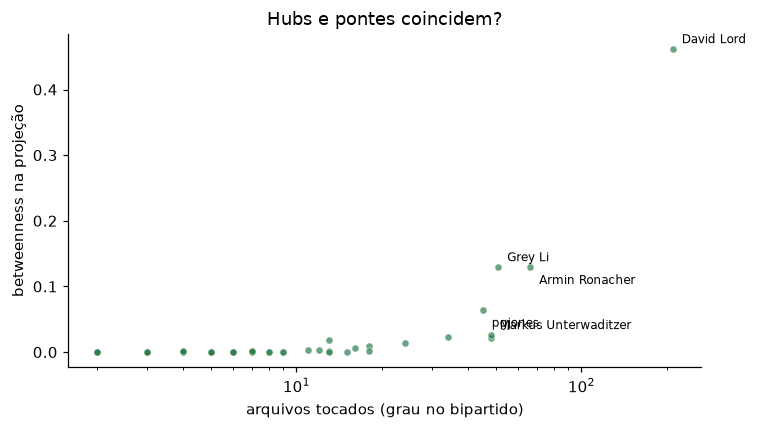

,autor,arquivos_tocados,grau_proj,betweenness_proj,eigenvector_proj,closeness_proj,clustering_proj,core_proj
123,David Lord,209,162.0,0.461,0.493,0.994,0.076,16.0
49,Armin Ronacher,66,112.0,0.129,0.374,0.762,0.134,16.0
180,Grey Li,51,115.0,0.129,0.309,0.773,0.133,16.0
538,pgjones,45,85.0,0.064,0.226,0.676,0.175,16.0
284,Markus Unterwaditzer,48,69.0,0.026,0.255,0.634,0.277,16.0
474,defuz,34,67.0,0.023,0.268,0.629,0.271,16.0
119,David Baumgold,48,59.0,0.022,0.246,0.610,0.284,16.0
420,ThiefMaster,13,51.0,0.018,0.117,0.593,0.282,15.0
378,Ron DuPlain,24,56.0,0.014,0.205,0.604,0.336,16.0
219,Jeff Widman,18,49.0,0.009,0.166,0.588,0.378,16.0


In [16]:
met_proj, info_m, gcc_S = an.metricas_projecao(S, autores)
met_autor = met_autor.join(met_proj, on="autor")
cols = ["autor", "arquivos_tocados", "grau_proj", "betweenness_proj", "eigenvector_proj", "closeness_proj", "clustering_proj", "core_proj"]
no_esq = met_autor[met_autor.grau_proj > 0]
rho_bip = met_autor[["arquivos_tocados", "betweenness"]].corr("spearman").iloc[0, 1]
rho_proj = no_esq[["arquivos_tocados", "betweenness_proj"]].corr("spearman").iloc[0, 1]
top_g, top_b = set(met_autor.nlargest(10, "arquivos_tocados").autor), set(met_autor.nlargest(10, "betweenness_proj").autor)
print(f"Spearman(grau, betweenness) no bipartido: {rho_bip:.3f} | na projeção: {rho_proj:.3f}")
print(f"top-10 em grau que também são top-10 em betweenness: {len(top_g & top_b)}")
print("pontes fora do top-10 de grau:", sorted(top_b - top_g))
print(f"clustering médio do esqueleto: {info_m['esq_clustering_medio']:.3f} | transitividade: {info_m['esq_transitividade']:.3f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(no_esq.arquivos_tocados, no_esq.betweenness_proj, s=22, color=VERDE, alpha=.7, edgecolor="white", linewidth=.5)
for k, r in enumerate(no_esq.nlargest(5, "betweenness_proj").itertuples()):
    ax.annotate(r.autor, (r.arquivos_tocados, r.betweenness_proj), fontsize=8, textcoords="offset points",
                xytext=(6, 4) if k % 2 == 0 else (6, -11))
ax.set_xscale("log"); ax.set_xlabel("arquivos tocados (grau no bipartido)"); ax.set_ylabel("betweenness na projeção")
ax.set_title("Hubs e pontes coincidem?")
plt.tight_layout(); plt.savefig(FIG_DIR / "grau_vs_betweenness.png"); plt.show()
met_autor.sort_values("betweenness_proj", ascending=False).head(10)[cols].round(3)

**Como ler.**
- No bipartido, grau e betweenness têm correlação de Spearman de 0,99: lá a betweenness **não acrescenta nada** ao grau. Na projeção a correlação cai para 0,88, então a medida traz alguma informação nova, mas pouca: 9 dos 10 maiores em grau também são os 10 maiores em betweenness. **Hubs e pontes são as mesmas pessoas**, e o risco se concentra nelas. A única "ponte silenciosa" é ThiefMaster, que tocou 13 arquivos mas divide código com 51 colegas.
- David Lord tem closeness de 0,99 (divide código com 162 dos 163 colegas do esqueleto) e **clustering de 0,08**: os colegas dele quase não trabalham entre si. É uma **estrela**, não uma equipe.
- O clustering médio alto (0,83) com transitividade baixa (0,29) confirma o desenho: autores periféricos formam pequenos grupos fechados em torno do hub, e os triângulos são raros entre os pares que passam pelo centro.

### 7.4 Núcleo duro: k-core, onion layers e k-truss na projeção *(semana 5)*

O k-core da projeção é o maior grupo em que cada pessoa divide código com pelo menos *k* outras do mesmo grupo. O k máximo (degeneracy) define o **núcleo duro**: quem conhece o projeto de forma transversal. As camadas (core number 1, 2, …) são as cascas da cebola, do contribuidor ocasional ao mantenedor. O **k-truss** é mais exigente: cada ligação precisa estar em pelo menos k−2 triângulos, ou seja, os pares trabalham com terceiros em comum, como uma equipe de verdade.

degeneracy da projeção (k máximo): 16 | autores no núcleo: 19
k-truss máximo: 17 com 19 autores
núcleo ainda ativo (commit nos últimos 730 dias): 1 de 19


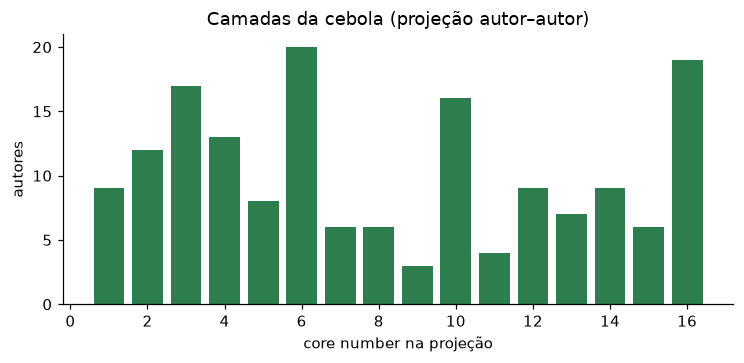

,autor,arquivos_tocados,grau_proj,ativo
123,David Lord,209,162.0,True
49,Armin Ronacher,66,112.0,False
180,Grey Li,51,115.0,False
284,Markus Unterwaditzer,48,69.0,False
119,David Baumgold,48,59.0,False
538,pgjones,45,85.0,False
474,defuz,34,67.0,False
378,Ron DuPlain,24,56.0,False
219,Jeff Widman,18,49.0,False
111,Daniel Neuhäuser,16,45.0,False


In [17]:
temporal_ativo, ativos_por_arquivo, info_t = an.metricas_temporais(arestas)   # usado aqui e na seção 7.8
met_autor["ativo"] = met_autor.autor.map(temporal_ativo)
nucleo_p = met_autor[met_autor.nucleo].sort_values("arquivos_tocados", ascending=False)
print(f"degeneracy da projeção (k máximo): {info_m['proj_k_max']} | autores no núcleo: {info_m['proj_nucleo_autores']}")
print(f"k-truss máximo: {info_m['proj_truss_max']} com {info_m['proj_truss_autores']} autores")
print(f"núcleo ainda ativo (commit nos últimos {info_t['janela_dias']} dias): {int(nucleo_p.ativo.sum())} de {len(nucleo_p)}")

camadas = no_esq.core_proj.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(camadas.index, camadas.values, color=VERDE)
ax.set_xlabel("core number na projeção"); ax.set_ylabel("autores"); ax.set_title("Camadas da cebola (projeção autor–autor)")
plt.tight_layout(); plt.savefig(FIG_DIR / "kcore_projecao.png"); plt.show()
nucleo_p[["autor", "arquivos_tocados", "grau_proj", "ativo"]]

**Como ler.** O núcleo duro tem degeneracy 16 e 19 autores, e o k-truss máximo (17) seleciona exatamente os mesmos 19: é um grupo coeso de verdade, em que cada par divide código com terceiros em comum. O dado decisivo é o atributo temporal: **só 1 dos 19 continua ativo**, o David Lord. O núcleo é **histórico**. O conhecimento transversal que existia em um grupo hoje está numa pessoa só, e é isso que a rede inteira, sem tempo, esconde.

### 7.5 Eficiência: quanto os caminhos se alongam sem essas pessoas *(semana 4)*

A GCC só cai quando a rede se parte. A **eficiência global** (média de 1/d entre pares, estimada com 300 origens) também cai quando os caminhos **se alongam**, que é o dano mais comum: o conhecimento continua alcançável, mas por mais intermediários.

In [18]:
rng_ef = np.random.default_rng(SEED)
fontes = list(rng_ef.choice(list(gcc_S), size=min(300, gcc_S.number_of_nodes()), replace=False))
def efic_sem(rem):
    H = S.copy(); H.remove_nodes_from(rem)
    return an.eficiencia(H, [f for f in fontes if f not in rem])
top_grau = met_autor.nlargest(5, "arquivos_tocados").autor.tolist()
top_btw = met_autor.nlargest(5, "betweenness_proj").autor.tolist()
base_ef = an.eficiencia(S, fontes)
ef = pd.DataFrame({"cenário": ["rede completa", "sem o 1º em grau", "sem os 5 primeiros em grau", "sem o 1º em betweenness", "sem os 5 primeiros em betweenness"],
                   "eficiência": [base_ef, efic_sem(top_grau[:1]), efic_sem(top_grau), efic_sem(top_btw[:1]), efic_sem(top_btw)]})
ef["queda_%"] = (1 - ef["eficiência"] / base_ef) * 100
ef.round(3)

,cenário,eficiência,queda_%
0,rede completa,0.542,0.000
1,sem o 1º em grau,0.467,13.826
2,sem os 5 primeiros em grau,0.345,36.359
3,sem o 1º em betweenness,0.467,13.826
4,sem os 5 primeiros em betweenness,0.304,44.011


**Como ler.** Sem o David Lord, o maior componente mal muda (seção 7.1), mas a eficiência cai **14%**: o conhecimento continua alcançável, só que por mais intermediários. Removendo 5 pessoas, a queda é de 36% pela ordem de grau e de **44% pela ordem de betweenness**. Os dois conjuntos de 5 diferem em uma pessoa (pgjones no lugar de David Baumgold), e o de betweenness é mais danoso **para a circulação**. Isso justifica usar betweenness para "por onde o conhecimento passa" e grau/gulosa para "quem cobre os arquivos" (próxima seção).

### 7.6 Quatro estratégias de remoção e perda ponderada *(semana 4)*

A seção 7 removeu autores por grau. Aqui comparo com outras ordens:

- **por betweenness na projeção:** remove primeiro as pontes;
- **gulosa adaptativa:** a cada passo remove quem deixaria mais arquivos órfãos **naquele momento**, recalculando após cada saída. É uma aproximação do pior caso (o *truck factor*);
- **perda de conhecimento (ponderada):** "órfão" exige que *todos* os autores saiam, então quem fez um commit de typo há dez anos ainda conta como cobertura. Na versão ponderada, o arquivo perde o conhecimento quando quem ficou soma menos de 20% dos commits dele.

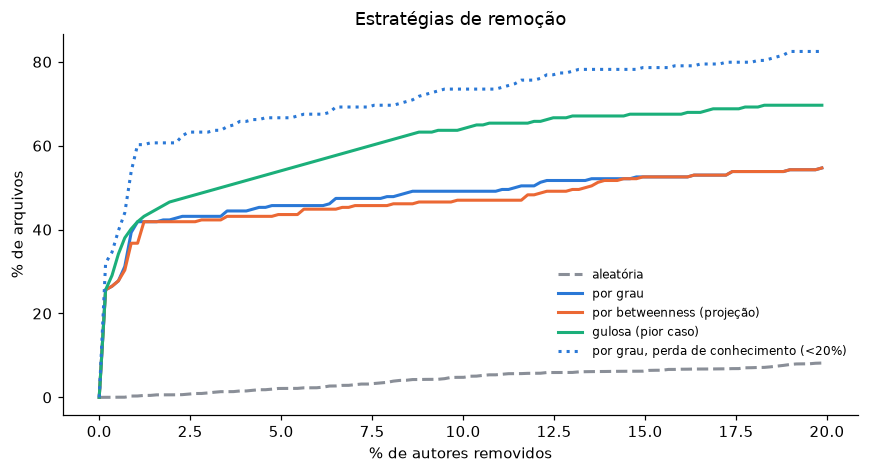

primeiros removidos pela gulosa: ['David Lord', 'David Baumgold', 'Markus Unterwaditzer', 'Armin Ronacher', 'pgjones']


,orfaos_direcionada_pct,orfaos_betweenness_pct,orfaos_gulosa_pct,conhecimento_direcionada_pct
autores p/ 25%,1.0,1.0,1.0,1.0
autores p/ 50%,65.0,76.0,19.0,5.0
% com 1 autor,25.6,25.6,25.6,32.1


In [19]:
K = int(0.20 * n_a)
ordem_btw = np.lexsort((-met_autor.arquivos_tocados.to_numpy(), -met_autor.betweenness_proj.to_numpy()))
W = an.matriz_incidencia(arestas, arquivos, autores, peso="commits")
curvas, _, ordem_gulosa = an.curvas_remocao(M, W, {"grau": ordem_dir, "betweenness": ordem_btw}, K, np.random.default_rng(SEED))

fig, ax = plt.subplots(figsize=(8, 4.4))
xx = curvas.pct_autores_removidos
ax.plot(xx, curvas.orfaos_aleatoria_pct, color=CINZA, lw=2, ls="--", label="aleatória")
ax.plot(xx, curvas.orfaos_direcionada_pct, color="#2a78d6", lw=2, label="por grau")
ax.plot(xx, curvas.orfaos_betweenness_pct, color="#eb6834", lw=2, label="por betweenness (projeção)")
ax.plot(xx, curvas.orfaos_gulosa_pct, color="#1baf7a", lw=2, label="gulosa (pior caso)")
ax.plot(xx, curvas.conhecimento_direcionada_pct, color="#2a78d6", lw=2, ls=":", label="por grau, perda de conhecimento (<20%)")
ax.set_xlabel("% de autores removidos"); ax.set_ylabel("% de arquivos"); ax.legend(frameon=False, fontsize=8, loc="lower right", bbox_to_anchor=(1, 0.12))
ax.set_title("Estratégias de remoção")
plt.tight_layout(); plt.savefig(FIG_DIR / "estrategias_remocao.png"); plt.show()

def autores_para(col, frac):
    ok = np.where(curvas[col].to_numpy() >= frac)[0]
    return int(ok[0]) if len(ok) else None
print("primeiros removidos pela gulosa:", [autores[j] for j in ordem_gulosa[:5]])
pd.DataFrame({col: {"autores p/ 25%": autores_para(col, 25), "autores p/ 50%": autores_para(col, 50), "% com 1 autor": round(curvas[col].iloc[1], 1)}
              for col in ["orfaos_direcionada_pct", "orfaos_betweenness_pct", "orfaos_gulosa_pct", "conhecimento_direcionada_pct"]})

### 7.7 Sucessores: quem pode assumir os arquivos críticos *(semana 6)*

Para cada autor dominante de arquivos críticos, o **sucessor por Jaccard** é quem tem o perfil de arquivos mais parecido com o dele. Mas parecido *no geral* não é o mesmo que conhecer *os arquivos críticos*. Por isso a tabela também mostra que fração dos críticos o sucessor já alterou e quem teria a maior cobertura.

In [20]:
suc = an.sucessores(arestas, met_arq.reset_index(names="arquivo"), met_autor)
suc

,autor,arquivos_criticos,sucessor_jaccard,jaccard,arquivos_em_comum,cobertura_criticos_pct,melhor_cobertura,melhor_cobertura_pct,sucessor_ativo
0,David Lord,33,Armin Ronacher,0.267281,58,3.030303,pgjones,27.272727,False


**Como ler.** O sucessor por Jaccard do David Lord é o Armin Ronacher (J = 0,27, 58 arquivos em comum): o perfil mais parecido no projeto todo. Mas ele está **inativo desde 2020** e alterou só 1 dos 33 arquivos críticos (3%). Quem mais cobre os críticos é pgjones, com 27%, também inativo. **Não existe sucessor pronto.** A recomendação concreta é parear um segundo mantenedor nos 33 arquivos críticos (workflows de CI, `pyproject.toml`, `__init__.py`, `sessions.py`). Esse caso mostra a limitação da Jaccard: ela mede semelhança global, não conhecimento dos arquivos que importam.

### 7.8 Janela temporal: quem ainda está no projeto *(semana 2, atributos de nó)*

Até aqui um autor que saiu em 2012 conta como cobertura. Cada autor recebe o atributo **ativo** quando fez algum commit nos 730 dias anteriores ao commit mais recente. A pergunta passa a ser: *quais arquivos já estão órfãos hoje, sem simular nenhuma saída?*

In [21]:
met_arq["autores_ativos"] = ativos_por_arquivo.reindex(met_arq.index).fillna(0).astype(int)
met_arq["dono_ativo"] = met_arq.autor_dominante.map(temporal_ativo)
sem_ativo = met_arq[met_arq.autores_ativos == 0]
print(f"referência: {info_t['data_referencia']} | autores ativos: {info_t['n_autores_ativos']} de {n_a} ({info_t['n_autores_ativos']/n_a:.1%})")
print(f"arquivos sem nenhum autor ativo: {len(sem_ativo)} ({len(sem_ativo)/n_f:.1%})")
print(f"críticos cujo dono está inativo: {int((met_arq.critico & ~met_arq.dono_ativo).sum())} de {int(met_arq.critico.sum())}")
print(f"arquivos que só os ativos cobrem com 1 pessoa: {(met_arq.autores_ativos == 1).mean():.1%}")
sem_ativo.sort_values("commits", ascending=False).head(10)[["n_autores", "commits", "autor_dominante"]]

referência: 2026-10-07 | autores ativos: 22 de 569 (3.9%)
arquivos sem nenhum autor ativo: 25 (10.7%)
críticos cujo dono está inativo: 0 de 33
arquivos que só os ativos cobrem com 1 pessoa: 76.9%


,n_autores,commits,autor_dominante
docs/patterns/urlprocessors.rst,4,4,Armin Ronacher
tests/templates/template_filter.html,3,3,Jon S. Stumpf
tests/templates/context_template.html,2,2,Armin Ronacher
docs/patterns/subclassing.rst,1,2,Anton Sarukhanov
docs/patterns/singlepageapplications.rst,2,2,Aly Sivji
tests/templates/_macro.html,2,2,Armin Ronacher
tests/templates/nested/nested.txt,2,2,Armin Ronacher
tests/templates/escaping_template.html,2,2,Armin Ronacher
tests/static/index.html,2,2,Armin Ronacher
tests/templates/simple_template.html,2,2,Armin Ronacher


**Como ler.** Dos 569 autores, só **22 (3,9%)** fizeram commits nos últimos dois anos. **25 arquivos (10,7%) já estão órfãos hoje**, sem simular nenhuma saída: são templates de teste e páginas de `docs/patterns` cujos autores saíram. E **76,9% dos arquivos são cobertos por uma única pessoa ativa**, ou seja, para 3/4 do projeto o *bus factor* atual é 1. Nenhum crítico tem dono inativo porque o dono de todos é o David Lord, que está ativo: o risco não está no passado, está no futuro.

### 7.9 Sensibilidade da definição de "arquivo crítico"

Os limiares de 80% e 3 commits são escolhas. Se a conclusão depender delas, ela não é confiável. A tabela varia os dois parâmetros.

In [22]:
sens = an.sensibilidade(met_arq)
print("dono mais frequente em todas as combinações:", sens.dono_mais_frequente.unique())
sens.pivot(index="min_commits", columns="limiar_pct", values="criticos_pct").round(1)

dono mais frequente em todas as combinações: <ArrowStringArray>
['David Lord']
Length: 1, dtype: str


limiar_pct,60,70,80,90
min_commits,,,,
1,56.4,46.2,39.3,33.8
3,46.8,31.4,21.2,12.8
5,45.4,28.5,20.0,10.0
10,37.6,22.6,15.1,9.7


**Como ler.** O **número** de arquivos críticos depende muito dos parâmetros (de 9,7% a 56,4% dos elegíveis), então não deve ser apresentado como um fato. Já a **conclusão** é estável: nas 16 combinações o dono mais frequente é o David Lord, e com pelo menos 3 commits e limiar de 70% ou mais ele é o **único** dono de arquivo crítico.

### 7.10 Subredes por pasta: onde o risco mora *(semana 2)*

Cada pasta induz uma subrede (seus arquivos e quem os alterou). A mesma concentração preocupa pouco em `docs/` e muito no código-fonte.

In [23]:
pastas = an.subredes_por_pasta(arestas, met_arq.reset_index(names="arquivo"))
pastas.round(1)

,pasta,arquivos,autores,ligacoes,densidade_pct,arquivos_1_autor_pct,criticos,criticos_pct,autor_principal,arquivos_do_principal_pct,orfaos_sem_principal_pct,sem_autor_ativo_pct
0,docs,87,408,891,2.5,18.4,5,7.1,David Lord,96.6,17.2,3.4
1,tests,61,140,343,4.0,31.1,0,0.0,David Lord,67.2,14.8,32.8
2,examples,42,11,64,13.9,61.9,10,52.6,David Lord,100.0,61.9,0.0
3,src/flask,26,93,187,7.7,7.7,8,33.3,David Lord,96.2,3.8,3.8
4,.github,9,9,17,21.0,66.7,6,100.0,David Lord,100.0,66.7,0.0
5,(raiz),7,14,22,22.4,42.9,4,80.0,David Lord,100.0,42.9,0.0


**Como ler.** Em `src/flask`, 96% dos arquivos têm o David Lord entre os autores, mas só **3,8%** ficariam órfãos sem ele: o código do framework é compartilhado (93 autores). O risco de exclusividade está na **infraestrutura**: `.github` (67% dos arquivos só dele), `examples` (62%) e os arquivos de configuração da raiz (43%). Em `tests`, 33% dos arquivos não têm nenhum autor ativo. Para o Flask, o ponto frágil é CI, release e configuração, não o código da biblioteca.

### 7.11 Efeito da amostragem: ler só os commits mais recentes *(semana 3)*

A aplicação permite analisar só os *N* commits mais recentes, e projetos grandes (`django`) foram analisados assim. Isso é uma **amostragem enviesada**: só aparece quem está ativo agora e só os arquivos tocados recentemente. Refaço a rede com recortes crescentes do mesmo histórico para ver quanto cada métrica depende disso.

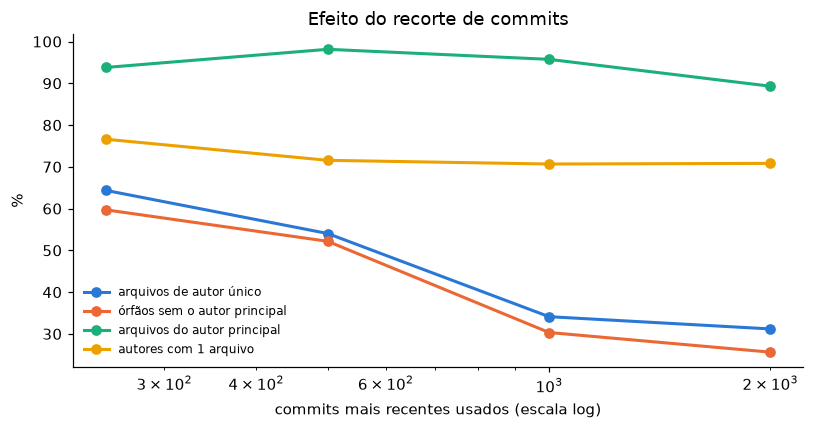

,commits,pct_do_historico,autores,arquivos,arquivos_vistos_pct,densidade_pct,autores_1_arquivo_pct,arquivos_1_autor_pct,autor_principal,arquivos_do_principal_pct,orfaos_sem_principal_pct
0,250,12.5,47,129,55.1,3.4,76.6,64.3,David Lord,93.8,59.7
1,500,25.1,109,161,68.8,2.1,71.6,54.0,David Lord,98.1,52.2
2,1000,50.1,283,211,90.2,1.4,70.7,34.1,David Lord,95.7,30.3
3,1996,100.0,569,234,100.0,1.1,70.8,31.2,David Lord,89.3,25.6


In [24]:
amostra = an.efeito_amostragem(registros)
fig, ax = plt.subplots(figsize=(7.5, 4))
for col, nome, cor in [("arquivos_1_autor_pct", "arquivos de autor único", "#2a78d6"), ("orfaos_sem_principal_pct", "órfãos sem o autor principal", "#eb6834"),
                       ("arquivos_do_principal_pct", "arquivos do autor principal", "#1baf7a"), ("autores_1_arquivo_pct", "autores com 1 arquivo", "#eda100")]:
    ax.plot(amostra.commits, amostra[col], marker="o", lw=2, color=cor, label=nome)
ax.set_xscale("log"); ax.set_xlabel("commits mais recentes usados (escala log)"); ax.set_ylabel("%")
ax.set_title("Efeito do recorte de commits"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "efeito_amostragem.png"); plt.show()
amostra.round(1)

**Como ler.** Com os 250 commits mais recentes (12,5% do histórico), a rede mostra **64% de arquivos de autor único** contra 31% no histórico completo, e **60% de órfãos** sem o autor principal contra 26%. O recorte recente **dobra** a concentração estimada, porque só enxerga quem está ativo hoje. Duas medidas são robustas à amostragem: a fração de autores com um único arquivo (~71% em todos os recortes) e a identidade do autor principal. Consequência para a comparação da seção 11: projetos analisados com `--max-commits` (o `django`) tendem a parecer mais concentrados do que são.

In [25]:
# exportação (alimenta a aplicação web depois)
met_autor.to_csv(DATA_DIR / "metricas_autores.csv", index=False)
curvas.to_csv(DATA_DIR / "curvas_estrategias.csv", index=False)
suc.to_csv(DATA_DIR / "sucessores.csv", index=False)
pastas.to_csv(DATA_DIR / "subredes_pastas.csv", index=False)
amostra.to_csv(DATA_DIR / "efeito_amostragem.csv", index=False)
met_arq.reset_index(names="arquivo").to_csv(DATA_DIR / "metricas_arquivos.csv", index=False)
curva = pd.DataFrame({"pct_autores_removidos": x, "orfaos_direcionada_pct": dir_ * 100, "orfaos_aleatoria_pct": alea * 100})
curva.to_csv(DATA_DIR / "curva_remocao.csv", index=False)
res["autores_removidos_%"] = res["autores_removidos_%"].astype(float)
res_gcc["autores_removidos_%"] = res_gcc["autores_removidos_%"].astype(float)
(pd.merge(res, res_gcc, on="autores_removidos_%", how="outer")      # junta pela porcentagem, não pela posição da linha
   .sort_values("autores_removidos_%").to_csv(DATA_DIR / "resultados_consolidados.csv", index=False))
print("CSVs gerados em", DATA_DIR.resolve()); sorted(p.name for p in DATA_DIR.iterdir())

CSVs gerados em C:\Users\Guilherme Martins\Documents\Projetos\study-opensource-projets-grafos\data


['arestas_autor_arquivo.csv',
 'comparacao_projetos.csv',
 'curva_remocao.csv',
 'curvas_estrategias.csv',
 'efeito_amostragem.csv',
 'metricas_arquivos.csv',
 'metricas_autores.csv',
 'resultados_consolidados.csv',
 'subredes_pastas.csv',
 'sucessores.csv']

## 8. Resultados interpretados à luz da pergunta

**Estrutura geral.** A rede do Flask tem 569 autores, 234 arquivos e 1.527 ligações, com densidade bipartida de apenas 1,1%. A distribuição de grau é muito desigual: 70,8% dos autores tocaram **um único arquivo** (contribuições pontuais), enquanto uma pessoa, David Lord, tocou 209 dos 234 arquivos (89%). Do lado dos arquivos, a mediana é de 3 autores, mas 31,2% dependem de **um só autor**.

**Quem conecta o projeto.** David Lord tem centralidade de grau de 0,89 e betweenness de 0,53, muito acima do segundo colocado (Armin Ronacher, 0,11). A rede é um único componente conexo. A betweenness alta indica que muitos caminhos mínimos passam por ele, mas a seção 7.1 mostra que removê-lo **não desconecta** a rede: o maior componente segue com 97,4% dos nós e a distância média sobe só de 3,41 para 3,84. O efeito dele é sobre a **cobertura de conhecimento** (arquivos órfãos), mais do que sobre a conectividade.

**Núcleo e periferia.** O k-core máximo é 7 e reúne 14 autores e 25 arquivos: o coração colaborativo, com contribuidores históricos. Na periferia (k = 1) estão 82 arquivos, 35% do total, cada um preso a um autor.

**Arquivos críticos.** Dos 156 arquivos com pelo menos 3 commits, 33 (21,2%) têm um autor com 80% ou mais dos commits, e **os 33 têm o mesmo autor dominante**. São sobretudo configuração e infraestrutura (`pyproject.toml`, `.pre-commit-config.yaml`, workflows do GitHub) e módulos centrais (`src/flask/__init__.py`, `testing.py`, `sessions.py`).

**Módulos de conhecimento.** A projeção dos arquivos (Jaccard ≥ 0,3, só arquivos com 2 ou mais autores) gera um esqueleto de 116 arquivos e 6 comunidades, com modularidade de 0,477. As comunidades acompanham a estrutura de pastas (código-fonte, padrões da documentação, tutorial e seus testes), o que indica que o conhecimento está organizado por área e não de forma difusa.

**Resposta à pergunta (simulação).**

| cenário | órfãos, remoção direcionada | órfãos, remoção aleatória | razão |
|---|---|---|---|
| 1 autor (o mais conectado) | 25,6% | 0,05%* | ~470× |
| 1% dos autores (6) | 41,9% | 0,3% | ~130× |
| 5% dos autores (28) | 45,7% | 2,1% | ~22× |
| 20% dos autores (113) | 54,7% | 8,2% | ~7× |

\* Para 1 autor, o valor é o esperado exato: 73 arquivos de autor único ÷ 569 autores ÷ 234 arquivos. A média de 200 sorteios (0,01%) é instável com um único autor removido.

Remover **apenas o autor mais conectado** deixa 25,6% dos arquivos sem nenhum autor restante. Com 6 pessoas, quase metade dos arquivos fica órfã. A curva sobe quase toda no início e depois achata: o risco está concentrado em pouquíssimas pessoas. Na remoção aleatória a perda é pequena porque a maioria dos autores tem grau 1 e toca arquivos que outros também tocam. A estrutura também se fragmenta: removendo 10% dos autores por grau, o maior componente cai para 83,4% da rede e surgem 37 componentes, contra 99,9% na remoção aleatória.

**O que as análises da seção 7.2 em diante acrescentam.**

- **O núcleo é histórico.** O k-core da projeção autor–autor (19 autores) coincide com o k-truss máximo, mas só 1 desses 19 continua ativo. Com a janela temporal, 76,9% dos arquivos têm uma única pessoa ativa por trás e 10,7% já não têm nenhuma.
- **O grau subestima o risco.** A remoção gulosa chega a 50% de arquivos órfãos com 19 autores, contra 65 pela ordem de grau. Na definição ponderada, bastam 5.
- **Hubs e pontes coincidem** (Spearman 0,88 na projeção; 9 dos 10 primeiros em comum), e o autor principal é o centro de uma estrela (clustering 0,08). Sem ele, a eficiência da rede de colaboração cai 14%.
- **Não há sucessor pronto.** O autor mais parecido (Jaccard) está inativo e tocou 3% dos arquivos críticos.
- **O risco mora na infraestrutura.** O código em `src/flask` é compartilhado (3,8% de órfãos sem o principal), enquanto `.github`, `examples` e a configuração da raiz dependem só dele.
- **A conclusão sobrevive aos limiares**, já que ele é o dono mais frequente nas 16 combinações. O número de críticos, por outro lado, não sobrevive.

**Conclusão:** em um projeto maduro e bem sucedido como o Flask, o conhecimento sobre os arquivos está **fortemente concentrado em um mantenedor**, e a análise temporal mostra que a concentração é ainda maior do que a rede histórica sugere: o grupo que já dividiu esse conhecimento (o k-core) saiu do projeto. A rede continua conectada sem ele, mas 25,6% dos arquivos ficam sem nenhum autor, a eficiência da colaboração cai 14% e ninguém ativo cobre os arquivos críticos. O risco é de **cobertura de conhecimento**, concentrado em CI, release e configuração, e não de fragmentação. A estrutura da rede revela o que a contagem de commits não mostra: quem é dono exclusivo, quem é ponte e quem poderia (ou não) assumir.

## 9. Limitações e artefatos reconhecidos

- **Commit não é conhecimento.** Uma aresta diz que a pessoa alterou o arquivo, não que o entende. Mudanças triviais (formatação, renomear variável) pesam como mudanças profundas. A versão ponderada (seção 7.6) reduz o problema, mas usa o mesmo commit como unidade; linhas alteradas (`git log --numstat`) seriam uma alternativa, com outros vieses.
- **Squash e revisão.** Se o projeto faz *squash merge*, o commit é creditado a quem abriu o PR, mas quem revisou e aprovou também conhece o código e não aparece na rede. Isso **superestima** a concentração no mantenedor.
- **Identidade.** A unificação por e-mail e nome é heurística. A mesma pessoa com dois e-mails vira dois autores, o que dilui a concentração e deixa o resultado otimista. Homônimos poderiam ser fundidos.
- **Renomeações.** Filtrar pelos arquivos do `HEAD` sem `--follow` perde o histórico de arquivos movidos, o que **subestima** o número de autores de arquivos antigos.
- **Janela de tempo.** A janela de 730 dias (seção 7.8) é uma escolha: um mantenedor sabático por 2 anos aparece como inativo. A referência é o commit mais recente, não a data de hoje, para não penalizar projetos estáveis.
- **Artefato de projeção.** A projeção autor–autor cria cliques em arquivos populares. O esqueleto (≥ 2 arquivos em comum) é um corte arbitrário, e a seção 7.2 mostra como os números mudam com ele.
- **Jaccard mede semelhança global**, não conhecimento dos arquivos críticos. Por isso a seção 7.7 mostra também a cobertura dos críticos.
- **Aproximações.** A betweenness usa 300 origens sorteadas e a eficiência é estimada com 300 origens. O ranking dos primeiros é estável; as posições finais não. A remoção gulosa é míope (otimiza um passo por vez), então é uma aproximação do pior caso, não o pior caso exato.
- **Amostragem.** Analisar só os commits recentes dobra a concentração estimada (seção 7.11). O `django` foi analisado com 15.000 commits e deve ser lido com isso em mente.
- **Topologia não é importância.** Um arquivo órfão em `tests/templates` vale menos que um em `src/flask`. Sem dados de uso ou de criticidade do código, a análise mede estrutura, não impacto. As subredes por pasta (seção 7.10) atenuam isso, mas não resolvem.

**Próximos passos:** usar linhas alteradas como peso, incluir revisores de PR via API do GitHub (rede multicamada: autoria + revisão), seguir renomeações com `--follow` e repetir a análise por janelas deslizantes para ver quando o núcleo se dissolveu.

## 10. Conteúdo do curso utilizado

Esta tabela alimenta diretamente a seção equivalente do README. "Onde" aponta a seção do notebook e a função em `analise.py`.

| conceito | semana | onde aparece | para que serviu |
|---|---|---|---|
| tipos de grafo, grafo bipartido ponderado | 2 | seções 2 e 4 · `analisar()` | modelar autores e arquivos como duas classes de nós |
| atributos de nó | 2 | seção 7.8 · `metricas_temporais()` | marcar autores ativos e achar arquivos já órfãos hoje |
| densidade | 2 | seções 4 e 7.10 · `analisar()`, `subredes_por_pasta()` | mostrar que a rede é esparsa (1,1%) e comparar pastas |
| grau, grau ponderado e distribuição de grau | 2 | seção 5.1 · `analisar()` | cauda longa: 70,8% dos autores tocam 1 arquivo; 31,2% dos arquivos têm 1 autor |
| subredes (subgrafo induzido) | 2 | seção 7.10 · `subredes_por_pasta()` | localizar o risco em `.github`, `examples` e configuração |
| matriz de adjacência / incidência | 2 e 6 | seção 5.2 · `matriz_incidencia()` | base das projeções (`M·Mᵀ`, `Mᵀ·M`) e da simulação de remoção |
| efeito da amostragem na estrutura | 3 | seção 7.11 · `efeito_amostragem()` | mostrar que o recorte recente dobra a concentração estimada |
| núcleo e periferia | 3 e 5 | seções 5.5 e 7.4 | separar mantenedores de contribuidores ocasionais |
| componentes conexos (GCC) | 4 | seções 5.3 e 7 · `simular()` no app | medir fragmentação antes e depois da remoção |
| caminhos, distância média e diâmetro | 4 | seção 7.1 | testar se o autor principal é ponte ou dono |
| eficiência global | 4 | seção 7.5 · `eficiencia()` | medir quanto os caminhos se alongam sem as pessoas centrais |
| clustering e triângulos | 4 | seção 7.3 · `metricas_projecao()` | identificar a estrutura em estrela em torno do mantenedor |
| centralidade de grau | 4 | seções 5.4 e 7.3 | alcance direto do autor |
| betweenness | 4 | seções 5.4, 7.3 e 7.6 · `metricas_projecao()` | identificar pontes e testar uma estratégia de remoção |
| eigenvector | 4 | seção 7.3 · `metricas_projecao()` | núcleo de decisão (ligado a outros bem ligados) |
| closeness | 4 | seção 7.3 · `metricas_projecao()` | quem está a poucos passos de todos |
| robustez: remoção aleatória × direcionada × gulosa | 4 | seções 7 e 7.6 · `curvas_remocao()` | responder à pergunta: quantas saídas deixam o projeto órfão |
| k-core, core number, degeneracy, onion layers | 5 | seções 5.5 e 7.4 · `metricas_projecao()` | núcleo duro de 19 autores, dos quais 1 está ativo |
| k-truss | 5 | seção 7.4 · `truss_max()` | confirmar que o núcleo é uma equipe coesa |
| projeção de redes bipartidas | 6 | seções 6.1 e 7.2 · `projecao_autores()` | rede de arquivos e rede de autores |
| similaridade de Jaccard | 6 | seções 6.1 e 7.7 · `projecao_autores()`, `sucessores()` | peso da projeção e sucessor de cada autor crítico |
| esqueleto por limiar | 6 | seções 6.1 e 7.2 · `projecao_autores()` | remover o artefato de projeção (cliques de arquivos populares) |
| comunidades (modularidade) | extra | seção 6.1 | módulos de conhecimento |

## 11. Comparação com outros projetos

O Flask foi analisado a fundo, mas a pergunta é sobre projetos open source em geral. A pasta `projetos/` traz o mesmo método (módulo `analise.py`, que reúne a lógica deste notebook) aplicado a outros cinco repositórios. Eles também podem ser explorados na aplicação (`streamlit run app.py`), que aceita o link de qualquer repositório público do GitHub.

**Cuidado:** `django/django` foi analisado só nos 15.000 commits mais recentes, então descreve esse recorte. Pela seção 7.11, recortes recentes tendem a **inflar** a concentração. Os outros cinco usam o histórico completo.

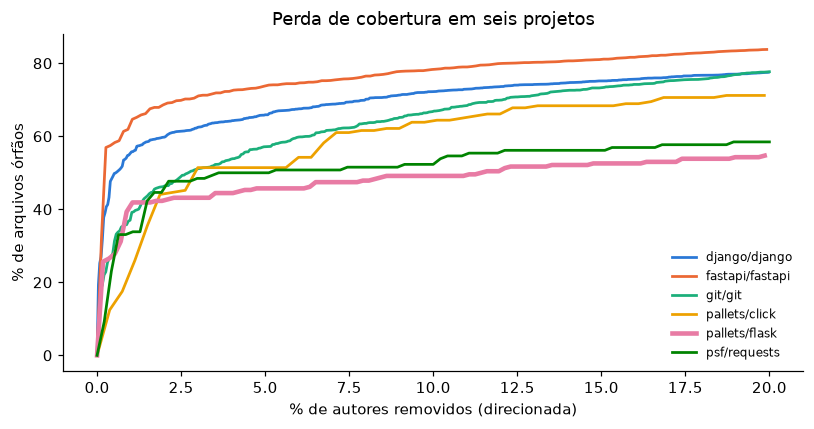

,projeto,commits lidos,autores,arquivos,arquivos do autor principal (%),arquivos de autor único (%),críticos (% dos elegíveis),órfãos sem o autor principal (%),órfãos sem 1 autor ao acaso (%),autores p/ 25% de órfãos,autores p/ 50% de órfãos
1,fastapi/fastapi,7806,763,3169,91.8,40.0,16.4,32.2,0.00,1,2
4,pallets/flask,3828,569,234,89.3,31.2,21.2,25.6,0.01,1,65
0,django/django,15000,2539,6274,62.1,35.2,31.1,19.3,0.00,2,15
3,pallets/click,2171,267,177,52.0,38.4,22.8,12.4,0.10,3,8
5,psf/requests,4862,470,130,59.2,28.5,13.9,9.2,0.25,3,17
2,git/git,61148,1935,4753,39.7,39.2,6.2,3.1,0.01,6,53


In [26]:
import json
linhas, curvas = [], {}
for f in sorted(Path("projetos").glob("*/resumo.json")):
    r = json.loads(f.read_text(encoding="utf-8"))
    curvas[r["repo"]] = pd.read_csv(f.parent / "curva_remocao.csv")
    linhas.append({"projeto": r["repo"], "commits lidos": r["funil_commits_lidos"], "autores": r["n_autores"], "arquivos": r["n_arquivos"],
                   "arquivos do autor principal (%)": round(r["pct_arquivos_autor_principal"], 1),
                   "arquivos de autor único (%)": round(r["pct_arquivos_1_autor"], 1),
                   "críticos (% dos elegíveis)": round(r["n_criticos"] / r["n_elegiveis"] * 100, 1),
                   "órfãos sem o autor principal (%)": round(r["orfaos_1_autor_pct"], 1),
                   "órfãos sem 1 autor ao acaso (%)": round(r["orfaos_1_autor_aleatoria_pct"], 2),
                   "autores p/ 25% de órfãos": r["autores_para_25pct_orfaos"], "autores p/ 50% de órfãos": r["autores_para_50pct_orfaos"]})
comp = pd.DataFrame(linhas).sort_values("órfãos sem o autor principal (%)", ascending=False)
comp.to_csv(DATA_DIR / "comparacao_projetos.csv", index=False)

fig, ax = plt.subplots(figsize=(7.5, 4))
PALETA = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]   # categórica validada para daltonismo
for (nome, c), cor in zip(curvas.items(), PALETA):
    ax.plot(c.pct_autores_removidos, c.orfaos_direcionada_pct, color=cor, lw=3 if nome == "pallets/flask" else 1.8, label=nome)
ax.set_xlabel("% de autores removidos (direcionada)"); ax.set_ylabel("% de arquivos órfãos")
ax.set_title("Perda de cobertura em seis projetos"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "comparacao_projetos.png"); plt.show()
comp

### Leitura da comparação

- **O padrão se repete.** Remover só o autor principal deixa de **3,1% (`git`) a 32,2% (`fastapi`)** dos arquivos órfãos, contra no máximo 0,25% na remoção de um autor ao acaso.
- **A gulosa sempre precisa de menos gente que a ordem por grau**, então o *truck factor* real é menor do que o ranking de contribuidores sugere: `fastapi` 2, `click` 6, `requests` 8, `django` 12, `flask` 19, `git` 42 autores para 50% de órfãos. Na definição ponderada, `flask` e `click` perdem o conhecimento de metade dos arquivos com 5 saídas.
- **O Flask não é o caso mais extremo.** O `fastapi` é mais concentrado: o autor principal toca 92% dos arquivos, dois autores bastam para metade dos órfãos e a eficiência da rede de colaboração cai 28% sem ele. O que distingue o Flask é a **base ativa minúscula** (22 autores ativos, núcleo de 19 com 1 ativo).
- **O `git` é o mais distribuído:** núcleo de 191 autores, 312 ativos e eficiência praticamente igual (−0,4%) sem o autor principal.
- **O `requests` tem a maior fração de arquivos já órfãos hoje** (14,6% sem nenhum autor ativo), com só 38 autores ativos de 470.
- **Artefato no `django`:** 1.379 dos 1.409 arquivos críticos são traduções (`locale/*.po` e `*.mo`), atualizadas em lote por um mantenedor na sincronização periódica das traduções. A concentração ali reflete o **fluxo de trabalho**, não falta de conhecimento do código. Os números de críticos do `django` estão inflados por essa pasta.
- A ordem entre projetos depende de decisões deste estudo (filtros, limiar de 80%, recorte de commits) e do modo de integração de cada projeto (squash, revisão). Serve para mostrar que o fenômeno é geral, não para ranquear projetos.